# 6.1 Correlation

**Goal:** measure association without confusing linear correlation, rank dependence, and causation.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Correlation](1_Correlation.ipynb)
2. [Covariance](2_Covariance.ipynb)
3. [Regression Analysis](3_Regression-Analysis.ipynb)
4. [Advanced Regression](4_Advanced-Regression.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. What is Correlation? Positive, Negative, and Zero Correlation

Correlation summarizes a specified form of association between paired variables. Positive linear correlation means larger values tend to accompany larger values; negative means the opposite. Zero Pearson correlation means zero standardized covariance, not absence of every relationship. A perfect positive/negative linear relation has correlation +1/−1 when both variances are positive.

**Worked example:** X is symmetric around zero and Y=X². The relationship is deterministic but Pearson correlation is zero in a symmetric sample. Constant variables have undefined correlation, not zero. Always align paired observations after joins and cleaning.

Linear r for a deterministic quadratic relation: 0.0


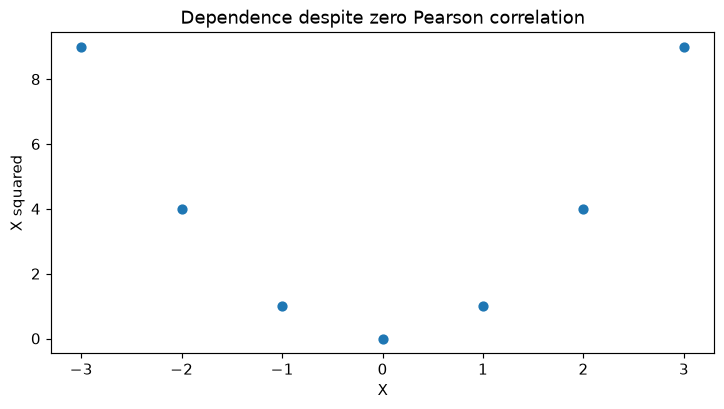

In [2]:
x=np.array([-3.,-2.,-1.,0.,1.,2.,3.]);y=x*x
print("Linear r for a deterministic quadratic relation:",stats.pearsonr(x,y).statistic)
fig,ax=plt.subplots();ax.scatter(x,y)
ax.set(title="Dependence despite zero Pearson correlation",xlabel="X",ylabel="X squared")
fig.tight_layout();plt.show()

## 2. Pearson Correlation

Population $\rho=\operatorname{Cov}(X,Y)/(\sigma_X\sigma_Y)$ requires finite positive variances. Sample $r=\sum_i(x_i-\bar x)(y_i-\bar y)/\sqrt{\sum_i(x_i-\bar x)^2\sum_i(y_i-\bar y)^2}$. It is unit-free, symmetric in X,Y, and unchanged by positive affine unit conversions; a negative multiplier flips its sign.

Pearson r describes linear association and is sensitive to outliers and mixtures. Its classical exact null t-test uses independent bivariate-normal observations under zero population correlation; computing r itself does not require normality. Repeated users, time trends, selective ranges, or missing pairs can distort inference and interpretation.

In [3]:
a=np.array([1.,2.,3.,4.,5.,6.]);b=np.array([1.,3.,2.,5.,4.,8.])
print("Pearson statistic/p:",stats.pearsonr(a,b))
assert np.isclose(stats.pearsonr(a,b).statistic,stats.pearsonr(10*a+7,b).statistic)

Pearson statistic/p: PearsonRResult(statistic=np.float64(0.8825200841010356), pvalue=np.float64(0.019891594630031453))


## 3. Spearman Rank Correlation and Kendall Rank Correlation

**Spearman** correlation is Pearson correlation of ranks, using average ranks for ties. It measures monotone association and can be useful for ordinal or nonlinear monotone relations. The shortcut $1-6\sum d_i²/[n(n²-1)]$ assumes no ties. Rank transformation reduces sensitivity to magnitudes but does not remove every influence or confounding issue.

**Kendall's tau** compares concordant and discordant pairs. Without ties, tau=(C−D)/choose(n,2). Tau-b adjusts for ties in either variable; it differs numerically from Spearman and Pearson and should not be compared as if the scales implied identical effect magnitude. P-values depend on sample size, ties, and approximation/exact method. Small-sample permutation methods can be preferable where valid.

In [4]:
print("Spearman:",stats.spearmanr(a,b))
print("Kendall tau-b:",stats.kendalltau(a,b))
print("Spearman equals rank Pearson:",stats.pearsonr(stats.rankdata(a),stats.rankdata(b)).statistic)

Spearman: SignificanceResult(statistic=np.float64(0.8857142857142858), pvalue=np.float64(0.01884548104956266))
Kendall tau-b: SignificanceResult(statistic=np.float64(0.7333333333333333), pvalue=np.float64(0.05555555555555555))
Spearman equals rank Pearson: 0.8857142857142857


## 4. Correlation vs. Causation

Association can arise from causal effects, common causes, selection, reverse causation, measurement artifacts, or coincident trends. A large correlation alone cannot distinguish these explanations. Randomized intervention or a defensible observational causal design is needed for effect claims.

**Example:** seasonal temperature can affect both beverage sales and outdoor activity; adjusting a regression is useful only if the causal adjustment set is appropriate. Conditioning on a collider can create association. High predictive usefulness does not imply changing the feature will change the outcome.

## 5. Partial Correlation

Partial Pearson correlation between X,Y controlling linearly for Z is correlation of residuals after regressing each on Z. With one control, $r_{XY.Z}=(r_{XY}-r_{XZ}r_{YZ})/\sqrt{(1-r_{XZ}²)(1-r_{YZ}²)}$ when denominators are positive.

It removes a linear association with controls, not all conditional dependence. A near-zero partial correlation implies conditional independence only under special models such as a joint multivariate normal with suitable nonsingularity. Control selection and causal reasoning remain essential.

In [5]:
n=150;z=rng.normal(size=n);x=2*z+rng.normal(size=n);y=3*z+rng.normal(size=n)
controls=np.column_stack([np.ones(n),z])
rx=x-controls@np.linalg.lstsq(controls,x,rcond=None)[0]
ry=y-controls@np.linalg.lstsq(controls,y,rcond=None)[0]
print("Marginal Pearson:",stats.pearsonr(x,y).statistic)
print("Partial after linear adjustment:",stats.pearsonr(rx,ry).statistic)

Marginal Pearson: 0.8553935488412833
Partial after linear adjustment: 0.005557394257906308


## AI/ML application and interpretation

Use association summaries for EDA, feature relationships, redundancy screening, and model interpretation. Fit any correlation-based feature selection on training data only. A low marginal correlation can hide nonlinear predictive information or interactions; a high one may be leakage or a proxy.

## Practice

1. Is r=0 equivalent to independence?
2. Which correlation is natural for ordered ranks with ties?
3. Why can two upward-trending time series correlate spuriously?
4. Does partial correlation establish a causal effect?

## Solutions

1. No. Y=X² with symmetric X is a counterexample; independence implies zero covariance only when the relevant moments exist, and the converse generally fails.
2. Spearman with average ranks or Kendall tau-b, depending on the intended interpretation.
3. Shared temporal structure can induce association without a direct relationship; dependence also invalidates simple IID inference.
4. No. It is a linear residual association conditional on selected controls, whose causal adequacy is a separate question.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](2_Covariance.ipynb).